In [4]:
from pathlib import Path
import pymupdf

PDF_PATH = next(Path("pdfs").glob("*.pdf"))   # prend le PDF du dossier pdfs
print("PDF utilisé :", PDF_PATH)

OUTPUT_DIR = Path("resultats_pdf")
TEXT_DIR, IMAGE_DIR = OUTPUT_DIR / "textes", OUTPUT_DIR / "images"
TEXT_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

textes = []
with pymupdf.open(PDF_PATH) as doc:
    for num, page in enumerate(doc, start=1):
        texte = page.get_text("text", sort=True)
        (TEXT_DIR / f"page_{num:03d}.txt").write_text(texte, encoding="utf-8")
        textes.append(f"===== PAGE {num} =====\n\n{texte}")
        vues = set()
        for info in page.get_images(full=True):
            xref = info[0]
            if xref in vues:
                continue
            vues.add(xref)
            img = doc.extract_image(xref)
            if img:
                (IMAGE_DIR / f"page_{num:03d}_image_{xref}.{img['ext']}").write_bytes(img["image"])

(OUTPUT_DIR / "texte_complet.txt").write_text("\n\n".join(textes), encoding="utf-8")
print(len(list(TEXT_DIR.iterdir())), "pages,", len(list(IMAGE_DIR.iterdir())), "images")

PDF utilisé : pdfs\attention is all you need.pdf
14 pages, 3 images


In [5]:
import torch, open_clip
from PIL import Image
from open_clip.tokenizer import SimpleTokenizer

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MODEL_NAME, PRETRAINED = "ViT-B-32", "laion2b_s34b_b79k"
model, _, preprocess = open_clip.create_model_and_transforms(MODEL_NAME, pretrained=PRETRAINED)
model = model.to(DEVICE).eval()
tokenizer = open_clip.get_tokenizer(MODEL_NAME)
bpe = SimpleTokenizer()

@torch.inference_mode()
def encoder_textes(textes):
    v = model.encode_text(tokenizer(textes).to(DEVICE)).float()
    return (v / v.norm(dim=-1, keepdim=True).clamp_min(1e-12)).cpu().tolist()

@torch.inference_mode()
def encoder_image(chemin):
    with Image.open(chemin) as im:
        t = preprocess(im.convert("RGB")).unsqueeze(0).to(DEVICE)
    v = model.encode_image(t).float()
    return (v / v.norm(dim=-1, keepdim=True).clamp_min(1e-12)).cpu().tolist()[0]

def decouper_texte(texte, taille=60, chevauchement=10):
    tokens = bpe.encode(texte)
    for d in range(0, len(tokens), taille - chevauchement):
        frag = bpe.decode(tokens[d:d + taille]).strip()
        if frag:
            yield frag
        if d + taille >= len(tokens):
            break

In [6]:
v_texte = encoder_textes(["a diagram of the transformer architecture"])[0]
print("Dimension :", len(v_texte))

Dimension : 512


In [7]:
import chromadb, hashlib, re

client = chromadb.PersistentClient(path="chroma_pdf")
collection = client.get_or_create_collection(
    "pdf_clip_vit_b32", embedding_function=None, metadata={"hnsw:space": "cosine"})

def numero_page(p):
    m = re.search(r"page_(\d+)", Path(p).stem)
    return int(m.group(1)) if m else -1

# Identifiant lié au contenu du PDF (permet de réindexer proprement)
document_id = hashlib.sha256(PDF_PATH.read_bytes()).hexdigest()[:24]
collection.delete(where={"document_id": document_id})

# --- Textes ---
ids, docs, metas = [], [], []
for f in sorted(TEXT_DIR.glob("page_*.txt")):
    page = numero_page(f)
    for i, frag in enumerate(decouper_texte(f.read_text(encoding="utf-8"))):
        ids.append(f"{document_id}:texte:{page}:{i}")
        docs.append(frag)
        metas.append({"type": "texte", "document_id": document_id,
                      "pdf": PDF_PATH.name, "page": page, "fragment": i})

for d in range(0, len(docs), 64):
    collection.upsert(ids=ids[d:d+64], documents=docs[d:d+64],
                      metadatas=metas[d:d+64],
                      embeddings=encoder_textes(docs[d:d+64]))
print(len(docs), "fragments de texte indexés")

# --- Images ---
nb_images = 0
for f in sorted(IMAGE_DIR.iterdir()):
    if f.suffix.lower() in {".png", ".jpg", ".jpeg", ".webp", ".bmp"}:
        collection.upsert(
            ids=[f"{document_id}:image:{f.name}"],
            embeddings=[encoder_image(f)],
            documents=[f"Image extraite du PDF : {f.name}"],
            metadatas=[{"type": "image", "document_id": document_id,
                        "pdf": PDF_PATH.name, "page": numero_page(f),
                        "source": str(f.resolve())}])
        nb_images += 1
print(nb_images, "images indexées")
print("Total dans ChromaDB :", collection.count())

172 fragments de texte indexés
3 images indexées
Total dans ChromaDB : 175


In [8]:
from IPython.display import display

def rechercher(texte=None, image=None, type_resultat=None, k=5):
    if (texte is None) == (image is None):
        raise ValueError("Fournir soit un texte, soit une image.")
    if type_resultat not in (None, "texte", "image"):
        raise ValueError("type_resultat doit être 'texte', 'image' ou None.")
    vecteur = encoder_textes([texte])[0] if texte is not None else encoder_image(image)
    opts = {"where": {"type": type_resultat}} if type_resultat else {}
    return collection.query(
        query_embeddings=[vecteur],
        n_results=min(k, collection.count()),
        include=["documents", "metadatas", "distances"], **opts)

def afficher_resultats(res):
    for r, (doc, m, dist) in enumerate(zip(res["documents"][0], res["metadatas"][0],
                                           res["distances"][0]), start=1):
        print(f"\n{r}. {m['type'].upper()} | page {m['page']} | similarité cosinus : {1 - dist:.3f}")
        if m["type"] == "image":
            with Image.open(m["source"]) as im:
                ap = im.convert("RGB")
                ap.thumbnail((500, 400))
                display(ap)
        else:
            print(doc)

=== Texte -> tout ===

1. TEXTE | page 10 | similarité cosinus : 0.677
the number of attention heads and the attention key and value dimensions , keeping the amount of computation constant , as described in section 3 . 2 . 2 . while single - head attention is 0 . 9 bleu worse than the best setting , quality also drops off with too many heads . 5 we used values

2. TEXTE | page 2 | similarité cosinus : 0.666
effective resolution due to averaging attention - weighted positions , an effect we counteract with multi - head attention as described in section 3 . 2 . self - attention , sometimes called intra - attention is an attention mechanism relating different positions of a single sequence in order to compute a representation of the sequence .

3. TEXTE | page 5 | similarité cosinus : 0.658
attention layers , or heads . for each of these we use dk = dv = dmodel / h = 6 4 . due to the reduced dimension of each head , the total

=== Texte -> images ===

1. IMAGE | page 3 | similarité cosinu

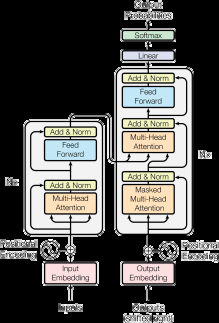


2. IMAGE | page 4 | similarité cosinus : 0.210


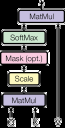


3. IMAGE | page 4 | similarité cosinus : 0.205


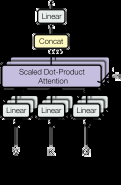


=== Image -> résultats ===

1. IMAGE | page 3 | similarité cosinus : 1.000


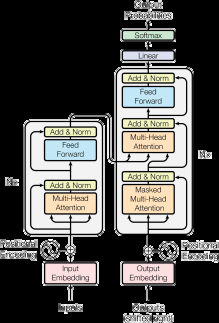


2. IMAGE | page 4 | similarité cosinus : 0.661


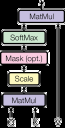


3. IMAGE | page 4 | similarité cosinus : 0.423


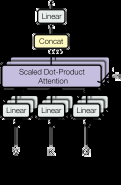

In [9]:
print("=== Texte -> tout ===")
afficher_resultats(rechercher(texte="multi-head attention", k=3))

print("\n=== Texte -> images ===")
afficher_resultats(rechercher(texte="transformer architecture diagram", type_resultat="image", k=3))

print("\n=== Image -> résultats ===")
chemin_image = next(IMAGE_DIR.iterdir())
afficher_resultats(rechercher(image=chemin_image, k=3))

In [10]:
from IPython.display import display

def rechercher(texte=None, image=None, type_resultat=None, k=5):
    if (texte is None) == (image is None):
        raise ValueError("Fournir soit un texte, soit une image.")
    if type_resultat not in (None, "texte", "image"):
        raise ValueError("type_resultat doit être 'texte', 'image' ou None.")
    vecteur = encoder_textes([texte])[0] if texte is not None else encoder_image(image)
    opts = {"where": {"type": type_resultat}} if type_resultat else {}
    return collection.query(
        query_embeddings=[vecteur],
        n_results=min(k, collection.count()),
        include=["documents", "metadatas", "distances"], **opts)

def afficher_resultats(res):
    for r, (doc, m, dist) in enumerate(zip(res["documents"][0], res["metadatas"][0],
                                           res["distances"][0]), start=1):
        print(f"\n{r}. {m['type'].upper()} | page {m['page']} | similarité cosinus : {1 - dist:.3f}")
        if m["type"] == "image":
            with Image.open(m["source"]) as im:
                ap = im.convert("RGB")
                ap.thumbnail((500, 400))
                display(ap)
        else:
            print(doc)

=== Texte -> tout ===

1. TEXTE | page 10 | similarité cosinus : 0.677
the number of attention heads and the attention key and value dimensions , keeping the amount of computation constant , as described in section 3 . 2 . 2 . while single - head attention is 0 . 9 bleu worse than the best setting , quality also drops off with too many heads . 5 we used values

2. TEXTE | page 2 | similarité cosinus : 0.666
effective resolution due to averaging attention - weighted positions , an effect we counteract with multi - head attention as described in section 3 . 2 . self - attention , sometimes called intra - attention is an attention mechanism relating different positions of a single sequence in order to compute a representation of the sequence .

3. TEXTE | page 5 | similarité cosinus : 0.658
attention layers , or heads . for each of these we use dk = dv = dmodel / h = 6 4 . due to the reduced dimension of each head , the total

=== Texte -> images ===

1. IMAGE | page 3 | similarité cosinu

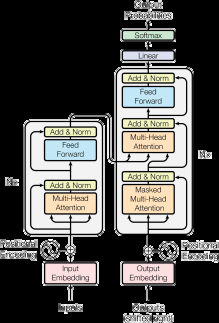


2. IMAGE | page 4 | similarité cosinus : 0.210


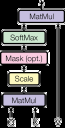


3. IMAGE | page 4 | similarité cosinus : 0.205


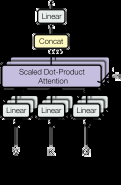


=== Image -> résultats ===

1. IMAGE | page 3 | similarité cosinus : 1.000


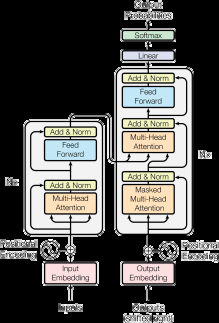


2. IMAGE | page 4 | similarité cosinus : 0.661


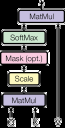


3. IMAGE | page 4 | similarité cosinus : 0.423


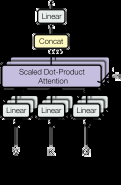

In [11]:
print("=== Texte -> tout ===")
afficher_resultats(rechercher(texte="multi-head attention", k=3))
print("\n=== Texte -> images ===")
afficher_resultats(rechercher(texte="transformer architecture diagram", type_resultat="image", k=3))
print("\n=== Image -> résultats ===")
afficher_resultats(rechercher(image=next(IMAGE_DIR.iterdir()), k=3))

In [12]:
from langchain_core.tools import tool

@tool
def retriever_tool(requete: str, type_resultat: str = "", chemin_image: str = "") -> str:
    """Recherche dans l'article 'Attention is all you need' (textes et images).
    - requete : question ou mots-clés en ANGLAIS (ignorée si chemin_image est fourni).
    - type_resultat : 'texte', 'image', ou '' pour chercher dans les deux.
    - chemin_image : chemin d'une image pour trouver des contenus similaires.
    Retourne les passages trouvés avec leur page, leur similarité et le chemin des images."""
    res = rechercher(
        texte=None if chemin_image else requete,
        image=chemin_image or None,
        type_resultat=type_resultat or None,
        k=5)
    lignes = []
    for doc, m, dist in zip(res["documents"][0], res["metadatas"][0], res["distances"][0]):
        if m["type"] == "image":
            lignes.append(f"[IMAGE p.{m['page']} sim={1 - dist:.2f}] {m['source']}")
        else:
            lignes.append(f"[TEXTE p.{m['page']} sim={1 - dist:.2f}] {doc}")
    return "\n".join(lignes)

print(retriever_tool.invoke({"requete": "scaled dot-product attention"}))

[TEXTE p.5 sim=0.61] attention ( q , k , v ) = softmax ( qkt √ dk ) v ( 1 ) the two most commonly used attention functions are additive attention [ 2 ], and dot - product ( multi plicative ) attention . dot - product attention is identical to our algorithm , except for the scaling
[TEXTE p.4 sim=0.56] consists of queries and keys of dimension dk , and values of dimension dv . we compute the dot products of the 3 scaled dot - product attention multi - head attention figure 2 : ( left ) scaled dot - product attention . ( right ) multi - head attention consists of several attention layers running in parallel
[TEXTE p.1 sim=0.56] started the effort to evaluate this idea . ashish , with illia , designed and implemented the first transformer models and has been crucially involved in every aspect of this work . noam proposed scaled dot - product attention , multi - head attention and the parameter - free position representation and became the other person involved
[TEXTE p.3 sim=0.55] also mo

C:\Users\DELL\AppData\Local\Temp\ipykernel_8556\3269532656.py:6: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  agent = create_react_agent(


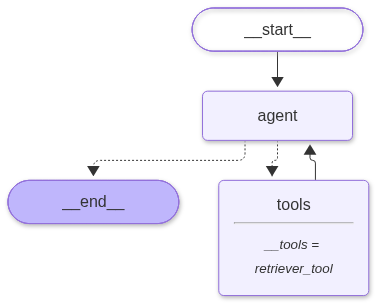

In [14]:
from langchain_ollama import ChatOllama
from langgraph.prebuilt import create_react_agent

llm = ChatOllama(model="qwen3:8b", temperature=0)

agent = create_react_agent(
    llm,
    tools=[retriever_tool],
    prompt=("Tu es un assistant expert de l'article 'Attention is all you need'. "
            "Utilise toujours retriever_tool pour chercher dans le document avant de répondre. "
            "Formule les requêtes de recherche en anglais. "
            "Cite les pages et donne les chemins des images pertinentes. "
            "Réponds en français."))

# Affichage du graphe (MIND = LLM, BODY = outil)
from IPython.display import Image as IPImage
display(IPImage(agent.get_graph().draw_mermaid_png()))

In [19]:
import re
from pathlib import Path
from PIL import Image
from ollama import ResponseError

def demander(question):
    print("QUESTION :", question)
    reponse_finale = ""
    try:
        for etape in agent.stream({"messages": [("user", question)]}, stream_mode="updates"):
            for noeud, contenu in etape.items():
                for msg in contenu["messages"]:
                    print(f"\n--- noeud : {noeud} ---")
                    if getattr(msg, "tool_calls", None):
                        print("Appel de l'outil :", msg.tool_calls[0]["args"])
                    else:
                        print(msg.content[:600])
                        if noeud == "agent":
                            reponse_finale = msg.content
    except ResponseError as e:
        print("ERREUR OLLAMA :", e.status_code, e.error)
        return

    # Afficher les images citées dans la réponse
    for chemin in set(re.findall(r"[A-Za-z]:\\[^\s\]\"']+\.(?:png|jpg|jpeg)", reponse_finale)):
        if Path(chemin).is_file():
            with Image.open(chemin) as im:
                ap = im.convert("RGB")
                ap.thumbnail((500, 400))
                display(ap)

demander("Montre-moi les images qui représentent l'architecture du Transformer.")

QUESTION : Montre-moi les images qui représentent l'architecture du Transformer.
ERREUR OLLAMA : 404 model 'qwen3:8b' not found
